In [ ]:
print("Student Performance Explorer")
print("My first machine learning research project!")

Student Performance Explorer
My first machine learning research project!



# Student Performance Explorer AI

## Project Overview
This project explores student academic performance using Python, Pandas, data visualization, and machine learning.

## Research Goal
Investigate whether earlier academic grades and other student-related factors can help predict final Mathematics grades.

## Dataset
UCI Student Performance Dataset — Mathematics records.

## Research Questions
1. How are first-period grades (G1) related to final grades (G3)?
2. How are second-period grades (G2) related to final grades (G3)?
3. Can a machine-learning model predict final grades accurately?

## Tools
- Python
- Google Colab
- Pandas
- Matplotlib
- Scikit-learn


In [ ]:
import os

path = "/content/drive/MyDrive/Colab Notebooks/student-mat.csv"
print("Dataset exists in Google Drive:", os.path.exists(path))

Dataset exists in Google Drive: True


In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/Colab Notebooks/student-mat.csv"
df = pd.read_csv(path, sep=";")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
print(df.head())

Dataset loaded successfully!
Rows and columns: (395, 33)
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


In [ ]:
print("Average final grade:", df["G3"].mean())
print("Lowest final grade:", df["G3"].min())
print("Highest final grade:", df["G3"].max())

Average final grade: 10.415189873417722
Lowest final grade: 0
Highest final grade: 20


In [ ]:
print(df["G3"].describe())

count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64


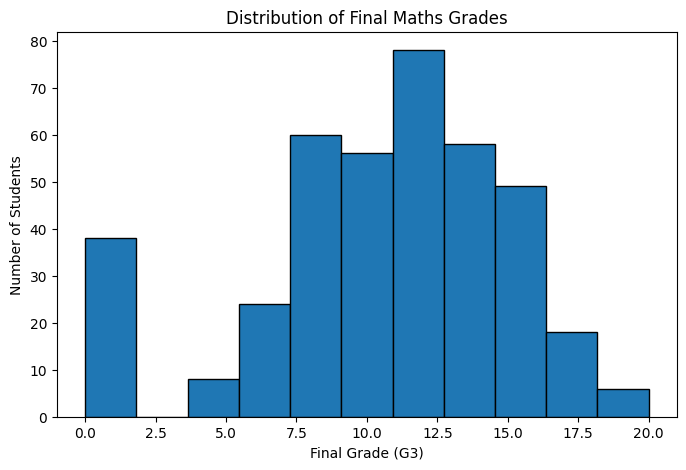

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["G3"], bins=11, edgecolor="black")

plt.title("Distribution of Final Maths Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.show()

In [ ]:
print("Missing values in each column:")
print(df.isnull().sum().sum())

Missing values in each column:
0


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
print(df.columns.tolist())

['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [ ]:
print(df.groupby("studytime")["G3"].mean())

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64


In [ ]:
print(df.groupby("failures")["G3"].mean())

failures
0    11.253205
1     8.120000
2     6.235294
3     5.687500
Name: G3, dtype: float64


In [ ]:
print(df["failures"].value_counts().sort_index())

failures
0    312
1     50
2     17
3     16
Name: count, dtype: int64


In [ ]:
print(df["absences"].corr(df["G3"]))

0.03424731615006931


In [ ]:
features = ["studytime", "failures", "absences"]
print(df[features + ["G3"]].corr()["G3"])

studytime    0.097820
failures    -0.360415
absences     0.034247
G3           1.000000
Name: G3, dtype: float64


In [ ]:
features = ["studytime", "failures", "absences"]

X = df[features]
y = df["G3"]

print("Feature data shape:", X.shape)
print("Target data shape:", y.shape)

Feature data shape: (395, 3)
Target data shape: (395,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (316, 3)
Testing features: (79, 3)
Training targets: (316,)
Testing targets: (79,)


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model training complete!")

Model training complete!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from sklearn.metrics import mean_absolute_error

y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", round(mae, 2))

Mean Absolute Error: 3.56


In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_pred)

print("Simple baseline MAE:", round(baseline_mae, 2))
print("Linear Regression MAE:", round(mae, 2))

Simple baseline MAE: 3.65
Linear Regression MAE: 3.56


In [ ]:
features_v2 = [
    "studytime", "failures", "absences",
    "age", "traveltime", "famrel",
    "freetime", "health"
]

X_v2 = df[features_v2]
y_v2 = df["G3"]

from sklearn.model_selection import train_test_split

X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_v2, y_v2,
    test_size=0.2,
    random_state=42
)

print("New feature shape:", X_v2.shape)
print("Training shape:", X_train_v2.shape)
print("Testing shape:", X_test_v2.shape)

New feature shape: (395, 8)
Training shape: (316, 8)
Testing shape: (79, 8)


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

model_v2 = LinearRegression()

model_v2.fit(X_train_v2, y_train_v2)

pred_v2 = model_v2.predict(X_test_v2)

mae_v2 = mean_absolute_error(y_test_v2, pred_v2)

print("Version 2 MAE:", round(mae_v2, 2))

Version 2 MAE: 3.57


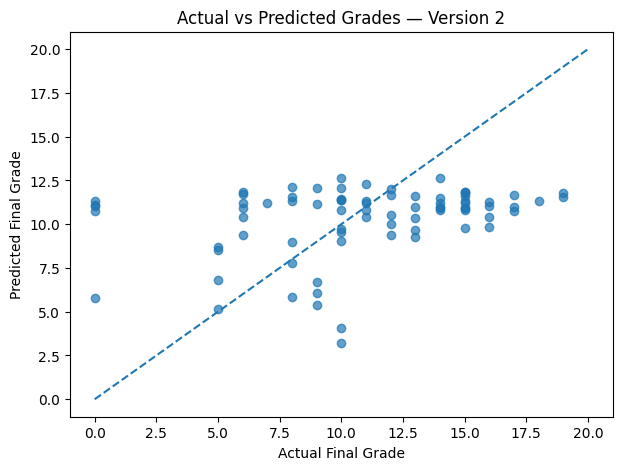

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(y_test_v2, pred_v2, alpha=0.7)

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Grades — Version 2")

plt.plot([0, 20], [0, 20], linestyle="--")

plt.show()

In [ ]:
print("Average actual grade:", round(y_test_v2.mean(), 2))
print("Average predicted grade:", round(pred_v2.mean(), 2))

print("Lowest prediction:", round(pred_v2.min(), 2))
print("Highest prediction:", round(pred_v2.max(), 2))

Average actual grade: 10.77
Average predicted grade: 10.29
Lowest prediction: 3.21
Highest prediction: 12.66


In [ ]:
# Exclude earlier-period grades and the final target
features_v3 = [
    col for col in df.columns
    if col not in ["G1", "G2", "G3"]
]

X_v3 = df[features_v3]
y_v3 = df["G3"]

from sklearn.model_selection import train_test_split

X_train_v3, X_test_v3, y_train_v3, y_test_v3 = train_test_split(
    X_v3,
    y_v3,
    test_size=0.2,
    random_state=42
)

print("Number of features:", len(features_v3))
print("Training shape:", X_train_v3.shape)
print("Testing shape:", X_test_v3.shape)
print("Earlier grades included:", "G1" in features_v3 or "G2" in features_v3)

Number of features: 30
Training shape: (316, 30)
Testing shape: (79, 30)
Earlier grades included: False


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Identify numerical and categorical columns
categorical_cols = X_train_v3.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_cols = [
    col for col in X_train_v3.columns
    if col not in categorical_cols
]

# Prepare each type of feature
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_cols),
        ("numeric", SimpleImputer(strategy="median"),
         numeric_cols)
    ]
)

# Build and train the pipeline
model_v3 = make_pipeline(
    preprocessor,
    LinearRegression()
)

model_v3.fit(X_train_v3, y_train_v3)

# Evaluate on the same held-out test set
pred_v3 = model_v3.predict(X_test_v3)
mae_v3 = mean_absolute_error(y_test_v3, pred_v3)

print("Categorical features:", len(categorical_cols))
print("Numerical features:", len(numeric_cols))
print("Version 3 MAE:", round(mae_v3, 2))

Categorical features: 17
Numerical features: 13
Version 3 MAE: 3.4


In [ ]:
results = {
    "Simple baseline": 3.65,
    "Version 1 (3 features)": 3.56,
    "Version 2 (8 features)": 3.57,
    "Version 3 (30 features)": round(mae_v3, 2)
}

for name, score in results.items():
    print(f"{name}: MAE = {score}")

Simple baseline: MAE = 3.65
Version 1 (3 features): MAE = 3.56
Version 2 (8 features): MAE = 3.57
Version 3 (30 features): MAE = 3.4
